## Markdown

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import date
from itertools import permutations, combinations, combinations_with_replacement
from collections import defaultdict
import dimod
import neal
import time

## Pre-Processing

In [2]:
# Read csv files
pnrs = pd.read_csv('COPA Data/PRMI_DM_ALL_PNRs.csv')
targets = pd.read_csv('COPA Data/PRMI-DM_TARGET_FLIGHTS.csv')
flights = pd.read_csv('COPA Data/PRMI-DM-AVAILABLE_FLIGHTS.csv')

# Quick edits to data
# Aggregate seat counts
targets['AVAIL_CNT'] = targets['C_AVAIL_CNT'] + targets['Y_AVAIL_CNT']
flights['AVAIL_CNT'] = flights['C_AVAIL_CNT'] + flights['Y_AVAIL_CNT']

# Drop unnecessary columns
pnrs = pnrs.drop(columns=['CREATION_DTZ', 'CABIN_CD', 'COS_CD', 'OPER_OD_ORIG_CD', 'DEP_DT', 'FLT_NUM', 'DEP_DTML', 'ARR_DTML'])
targets = targets.drop(columns=['DEP_DT', 'DEP_DTML', 'ARR_DTML', 'C_CAP_CNT', 'C_AUL_CNT', 'C_PAX_CNT', 'Y_CAP_CNT', 'Y_AUL_CNT', 'Y_PAX_CNT', 'C_AVAIL_CNT', 'Y_AVAIL_CNT'])
flights = flights.drop(columns=['DEP_DT', 'DEP_DTML', 'ARR_DTML', 'C_CAP_CNT', 'C_AUL_CNT', 'C_PAX_CNT', 'Y_CAP_CNT', 'Y_AUL_CNT', 'Y_PAX_CNT', 'C_AVAIL_CNT', 'Y_AVAIL_CNT'])
# Convert DTMZ columns to datetime
pnrs['DEP_DTMZ'] = pd.to_datetime(pnrs['DEP_DTMZ'])
pnrs['ARR_DTMZ'] = pd.to_datetime(pnrs['ARR_DTMZ'])
targets['DEP_DTMZ'] = pd.to_datetime(targets['DEP_DTMZ'])
targets['ARR_DTMZ'] = pd.to_datetime(targets['ARR_DTMZ'])
flights['DEP_DTMZ'] = pd.to_datetime(flights['DEP_DTMZ'])
flights['ARR_DTMZ'] = pd.to_datetime(flights['ARR_DTMZ'])

targets = targets.sort_values(by="ARR_DTMZ")


In [3]:
# Passengers associated with the cancelled flight
can_fl = pnrs.merge(
    targets[["DEP_KEY", "CHANGE_TYPE"]],
    on="DEP_KEY",
    how="inner"
)

#can_fl.to_csv('Cancelled_Passengers.csv')

In [4]:
def create_route(orig, dest, start_time, path):
    '''
    Generates possible routes by recursively searching flights dataset until end destination is reached
    Fails if no route is found in under 48 hours from start_time
    Returns a list of all found routes
    '''
    routes = []
    test_path = path.copy() # Copy the path
    path_cities = []
    # Find earliest departure time for flights
    if len(test_path) > 0:
        last_flight_time = flights[flights['DEP_KEY'] == test_path[-1]].iloc[0]['ARR_DTMZ']
    else:
        last_flight_time = pd.Timestamp(year=2000, month=1, day=1)

    for flight in test_path:
        path_cities.append(flights[flights['DEP_KEY'] == flight].iloc[0]['ORIG_CD'])

    filtered_flights = flights[flights['ORIG_CD'] == orig] # Filter wrong origin codes
    filtered_flights = filtered_flights[~filtered_flights['DEST_CD'].isin(path_cities)] # Filter flights that go to a previously visited city
    # filtered_flights = filtered_flights[filtered_flights['DEP_DTMZ'] > last_flight_time] # Filter too early flights

    # Filter too early or late flights
    indices_to_drop = []
    for idx, flight in filtered_flights.iterrows():
        if last_flight_time.year == 2000:
            connection_hours = 1
        else:
            connection_hours = (flight['DEP_DTMZ'] - last_flight_time).value / 3.6e12 # Convert connection miliseconds to hours
        delay_hours = (flight['ARR_DTMZ'] - start_time).value / 3.6e12 # Convert total reroute miliseconds to hours
        if flight['DEP_DTMZ'] < start_time or delay_hours > 48 or connection_hours < 1:
            indices_to_drop.append(idx)
    filtered_flights = filtered_flights.drop(indices_to_drop)

    # Find new flights
    test_path.append('') # Add element to replace with test cities
    for idx, flight in filtered_flights.iterrows():
        test_path[-1] = flight['DEP_KEY'] # Insert flight into path being tested
        if flight['DEST_CD'] == dest: # Destination found
            routes.append(test_path.copy())
            continue
        # Recursive search
        subroutes = create_route(flight['DEST_CD'], dest, start_time, test_path)
        if len(subroutes) > 0:
            for row in subroutes:
                routes.append(row)

    return routes

In [5]:
alt_routes = []

# Remove cancelled flights from the dataset
for key in targets['DEP_KEY']:
    flights = flights[flights['DEP_KEY'] != key]

# Iterate through cancelled flights
# Find new routes leading to destination city
# Skip route as soon as it takes >48H
# Store routes in a list
for idx, irop in targets.iterrows():
    routes = create_route(irop['ORIG_CD'], irop['DEST_CD'], irop['DEP_DTMZ'], [])
    for row in routes:
        alt_routes.append(row)
        
alt_routes = [list(row) for row in set(tuple(row) for row in alt_routes)]

## Creating QUBO

In [ ]:
flight_info = flights.set_index('DEP_KEY')[['ORIG_CD', 'DEST_CD', 'AVAIL_CNT', 'DEP_DTMZ', 'ARR_DTMZ']].to_dict('index')

# Organize routes by O/D for quick access
routes_by_od = defaultdict(list)
for route in alt_routes:
    if not route: continue
    start_f, end_f = route[0], route[-1]
    if start_f in flight_info and end_f in flight_info:
        r_orig = flight_info[start_f]['ORIG_CD']
        r_dest = flight_info[end_f]['DEST_CD']
        routes_by_od[(r_orig, r_dest)].append(route)

def calculate_pain_cost(pax_row, route, P_cvm=15.0, P_delay=2.0):
    """Calculates C_p,i based on delay and passenger priority."""
    orig_arr = pax_row['ARR_DTMZ']
    new_arr = flight_info[route[-1]]['ARR_DTMZ']
    
    delay_hrs = max(0, (new_arr - orig_arr).total_seconds() / 3600.0)
    # Higher CVM reduces energy, making the route more 'attractive' to the annealer
    return (P_delay * delay_hrs) - (P_cvm * pax_row['CVM'])

def build_batch_qubo(batch_df, flight_caps, routes_map, P1=100000, P2=3000):
    """Builds a QUBO for a subset of passengers."""
    Q = defaultdict(float)
    p_vars = defaultdict(list)
    f_vars = defaultdict(list)

    # One route per passenger
    for _, pax in batch_df.iterrows():
        pid = pax['RECLOC']
        p_count = pax['PAX_CNT']
        possible_paths = routes_map.get((pax['ORIG_CD'], pax['DEST_CD']), [])
        
        for i, route in enumerate(possible_paths):
            var = f"x_{pid}_{i}"
            p_vars[pid].append(var)
            for f_key in route:
                f_vars[f_key].append((var, p_count))
            
            # Diagonal: Cost + One Route penalty
            Q[(var, var)] += calculate_pain_cost(pax, route) - P1
            
        # Off-diagonal: High penalty if two routes selected for same passenger
        pax_vars = p_vars[pid]
        for i in range(len(pax_vars)):
            for j in range(i + 1, len(pax_vars)):
                Q[tuple(sorted((pax_vars[i], pax_vars[j])))] += 2 * P1

    # Seat Capacity
    for f_key, usages in f_vars.items():
        if f_key not in flight_caps: continue
        cap = flight_caps[f_key]['AVAIL_CNT']
        
        # Add Slack variables
        slack_vars = []
        if cap > 0:
            for k in range(int(np.floor(np.log2(cap))) + 1):
                s_var, s_coeff = f"s_{f_key}_{k}", 2**k
                slack_vars.append((s_var, s_coeff))
        
        all_terms = usages + slack_vars
        for v, w in all_terms:
            Q[(v, v)] += P2 * (w**2 - 2 * cap * w) # Diagonal addition
            
        for i in range(len(all_terms)):
            for j in range(i + 1, len(all_terms)):
                v1, w1 = all_terms[i]
                v2, w2 = all_terms[j]
                Q[tuple(sorted((v1, v2)))] += 2 * P2 * w1 * w2

    return Q


# Sort by CVM to prioritize high-value passengers
pax_pool_df = can_fl.sort_values(by='CVM', ascending=False)
pax_pool_list = pax_pool_df.to_dict('records')

batch_size = 50
all_assignments = []
double_booking_count = 0 
sampler = neal.SimulatedAnnealingSampler()

print(f"Starting batch processing for {len(pax_pool_list)} passengers...")

for i in range(0, len(pax_pool_list), batch_size):
    current_batch = pd.DataFrame(pax_pool_list[i : i + batch_size])
    q_dict = build_batch_qubo(current_batch, flight_info, routes_by_od)
    print(f"Solving Batch {i//batch_size + 1} ({len(current_batch)} pax)...")
    
    if not q_dict: continue
    
    sampleset = sampler.sample_qubo(q_dict, num_reads=150, num_sweeps=500)
    best_sample = sampleset.first.sample
    
    for _, pax in current_batch.iterrows():
        pid = pax['RECLOC']
        paths = routes_by_od.get((pax['ORIG_CD'], pax['DEST_CD']), [])
        
        assigned_to_pax = 0
        for j, route in enumerate(paths):
            if best_sample.get(f"x_{pid}_{j}", 0) == 1:
                pax_res = pax.to_dict()
                assigned_to_pax += 1
                pax_res['ASSIGNED_ROUTE'] = route
                pax_res['NEW_DEST'] = flight_info[route[-1]]['DEST_CD']
                all_assignments.append(pax_res)
                # Update capacity
                for f_key in route:
                    flight_info[f_key]['AVAIL_CNT'] -= pax['PAX_CNT']
        
        # Check if the QUBO solution double booked
        if assigned_to_pax > 1:
            double_booking_count += (assigned_to_pax - 1)

## Metrics and Graphs


📊  SOLUTION PERFORMANCE METRICS
Total Passengers Needing Help:    15096
Passengers Successfully Seated:   11171
Percentage Re-accommodated:       74.00%
High-Value Pax (CVM > 2.5) Seated: 7033 / 8562
Unseated Passengers:   3036
Double Bookings:       0
--------------------------------------------------
✅ All assignments respect uniqueness constraints.


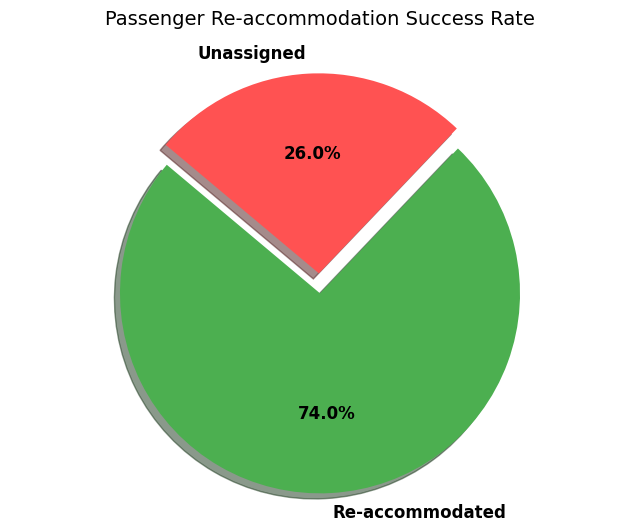

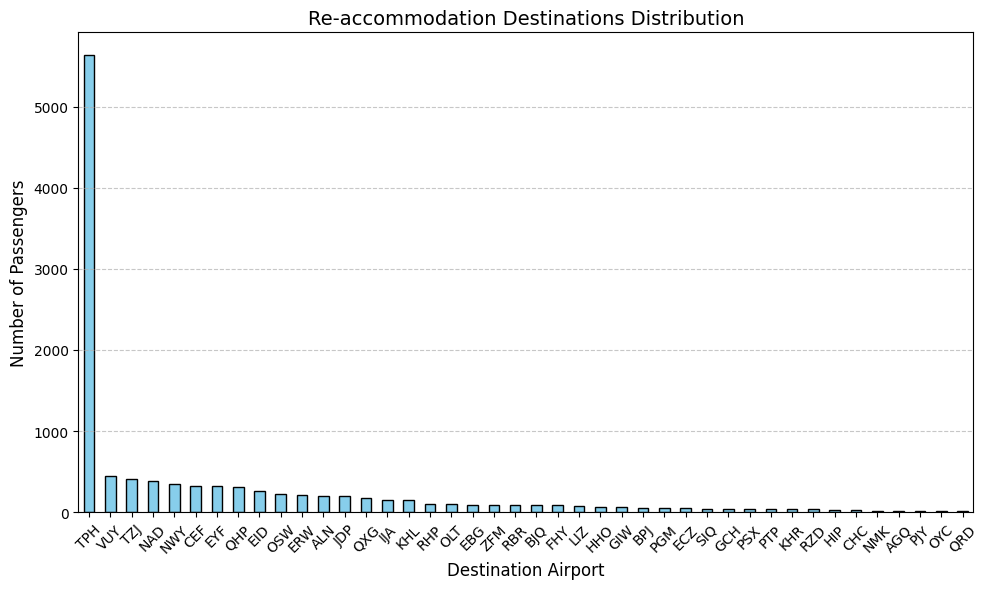

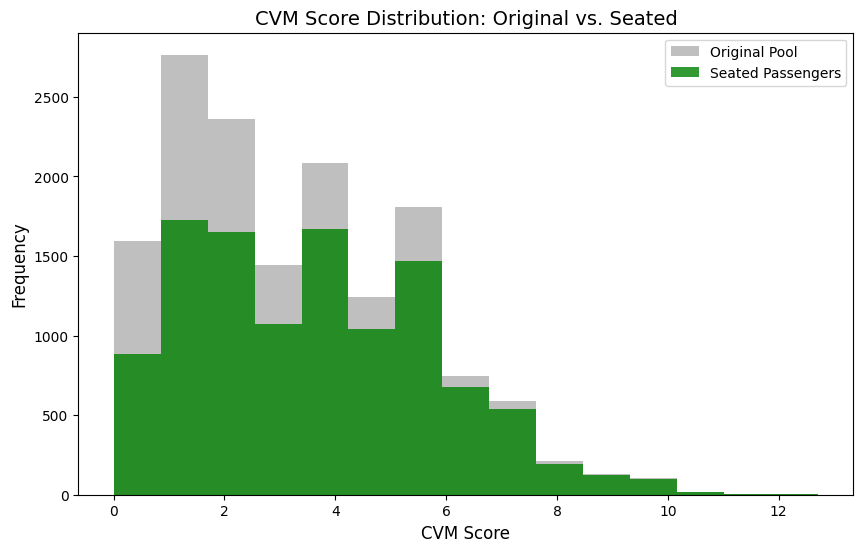

In [23]:
results_df = pd.DataFrame(all_assignments)
assigned_pids = set(results_df['RECLOC']) if not results_df.empty else set()
all_pids = set(pax_pool_df['RECLOC'])

unseated_pids = all_pids - assigned_pids


total_pax = len(can_fl)
seated_pax = len(results_df)
seated_pax = len(results_df)
unseated_pax = total_pax - seated_pax
# Re-accommodation Percentage
percent_seated = (seated_pax / total_pax) * 100


# High CVM Success (> 2.5)
high_cvm_total = can_fl[can_fl['CVM'] > 2.5].shape[0]
high_cvm_seated = results_df[results_df['CVM'] > 2.5].shape[0] if not results_df.empty else 0

print("\n" + "="*50)
print("📊  SOLUTION PERFORMANCE METRICS")
print("="*50)
print(f"Total Passengers Needing Help:    {total_pax}")
print(f"Passengers Successfully Seated:   {seated_pax}")
print(f"Percentage Re-accommodated:       {percent_seated:.2f}%")
print(f"High-Value Pax (CVM > 2.5) Seated: {high_cvm_seated} / {high_cvm_total}")
print(f"Unseated Passengers:   {len(unseated_pids)}")
print(f"Double Bookings:       {double_booking_count}")
print("-" * 50)

if double_booking_count > 0:
    print(f"WARNING: {double_booking_count} constraint violations detected. Consider increasing P1.")
else:
    print("All assignments respect uniqueness constraints.")

if not results_df.empty:
    plt.figure(figsize=(8, 6))
    labels = ['Re-accommodated', 'Unassigned']
    sizes = [seated_pax, unseated_pax]
    colors = ['#4CAF50', '#FF5252'] # Green for success, Red for failure
    explode = (0.1, 0) 
    
    plt.pie(sizes, explode=explode, labels=labels, autopct='%1.1f%%',
            shadow=True, startangle=140, colors=colors, 
            textprops={'fontsize': 12, 'weight': 'bold'})
    
    plt.title('Passenger Re-accommodation Success Rate', fontsize=14, pad=20)
    plt.axis('equal')

    dest_counts = results_df['NEW_DEST'].value_counts()
    plt.figure(figsize=(10, 6))
    dest_counts.plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title('Re-accommodation Destinations Distribution', fontsize=14)
    plt.xlabel('Destination Airport', fontsize=12)
    plt.ylabel('Number of Passengers', fontsize=12)
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    
    # CVM Comparison
    plt.figure(figsize=(10, 6))
    plt.hist(can_fl['CVM'], bins=15, alpha=0.5, label='Original Pool', color='grey')
    plt.hist(results_df['CVM'], bins=15, alpha=0.8, label='Seated Passengers', color='green')
    plt.title('CVM Score Distribution: Original vs. Seated', fontsize=14)
    plt.xlabel('CVM Score', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.legend()
    

Simulating optimization across different delay thresholds...
Delay Limit: 2h | Time: 8.41s | Success: 3.8%
Delay Limit: 4h | Time: 12.73s | Success: 16.1%
Delay Limit: 8h | Time: 16.49s | Success: 24.5%
Delay Limit: 12h | Time: 20.03s | Success: 34.7%
Delay Limit: 18h | Time: 27.86s | Success: 43.8%
Delay Limit: 24h | Time: 44.42s | Success: 59.9%
Delay Limit: 30h | Time: 51.93s | Success: 64.0%
Delay Limit: 36h | Time: 68.18s | Success: 67.8%
Delay Limit: 42h | Time: 80.65s | Success: 71.7%
Delay Limit: 48h | Time: 103.97s | Success: 73.6%

📈 Evaluation complete. Graphs saved as 'performance_by_delay.png' and 'success_vs_time.png'.


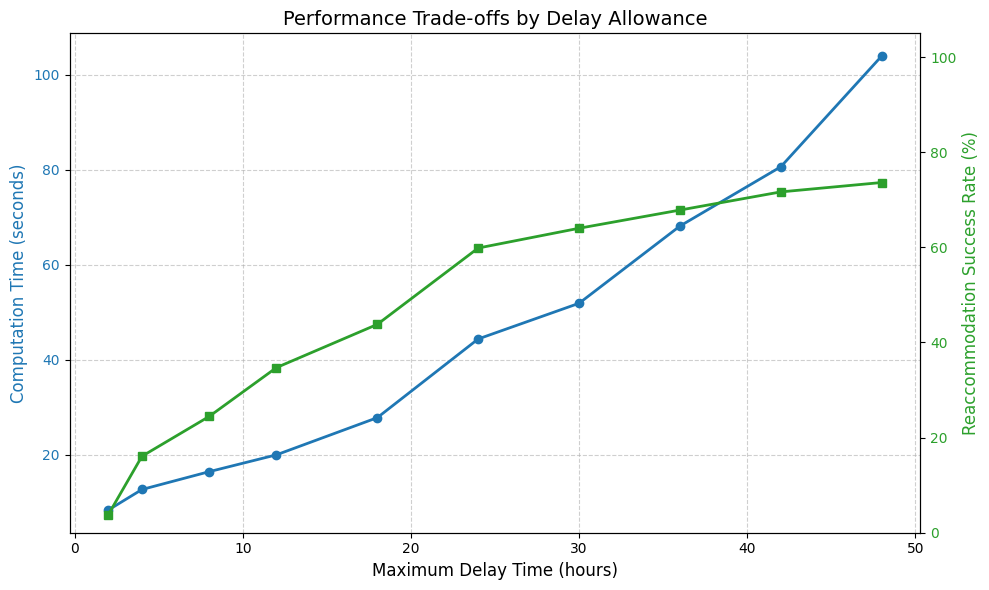

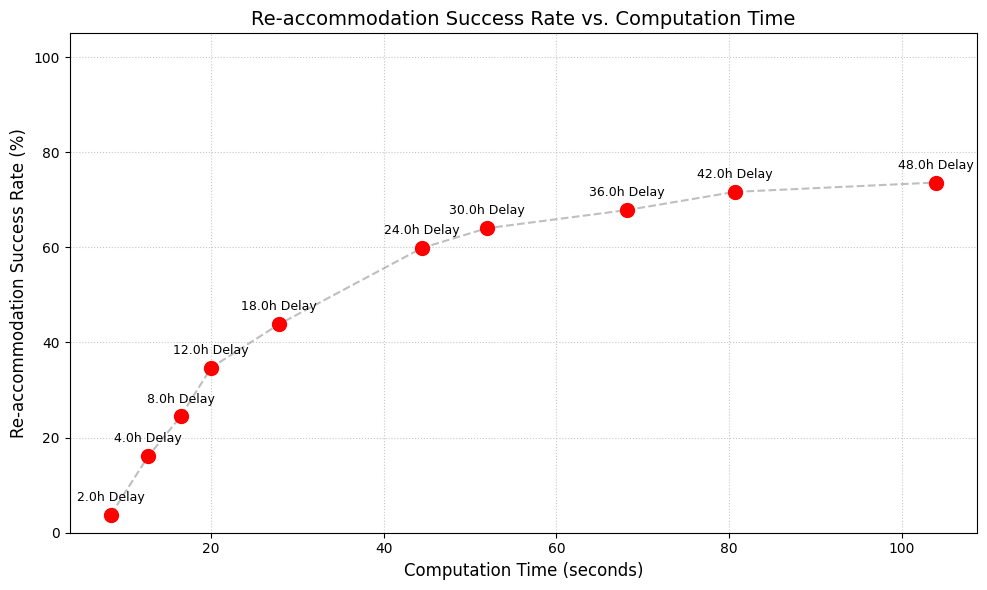

In [24]:
can_fl['ARR_DTMZ'] = pd.to_datetime(can_fl['ARR_DTMZ'])
flights['ARR_DTMZ'] = pd.to_datetime(flights['ARR_DTMZ'])
flight_info = flights.set_index('DEP_KEY')[['ORIG_CD', 'DEST_CD', 'AVAIL_CNT', 'ARR_DTMZ']].to_dict('index')

def run_irops_optimization(pax_df, delay_limit_hours):
    """
    Runs the batched QUBO solver for a specific delay limit.
    Returns: (comp_time, success_rate)
    """
    start_time = time.time()
    
    pax_pool = pax_df.sort_values(by='CVM', ascending=False).to_dict('records')
    current_flight_info = {k: v.copy() for k, v in flight_info.items()}
    
    batch_size = 20
    all_assignments = []
    sampler = neal.SimulatedAnnealingSampler()

    for i in range(0, len(pax_pool), batch_size):
        batch = pd.DataFrame(pax_pool[i : i + batch_size])
        
        # Build batch routes that fit within the delay_limit
        batch_routes_map = defaultdict(list)
        for _, p in batch.iterrows():
            orig, dest = p['ORIG_CD'], p['DEST_CD']
            p_orig_arr = p['ARR_DTMZ']
            
            # Find possible routes for this origin and destination from alt_routes
            for route in alt_routes:
                if not route: continue
                # Check if route matches passenger origin/destination and is within delay limit
                f_start, f_end = route[0], route[-1]
                if (flight_info[f_start]['ORIG_CD'] == orig and 
                    flight_info[f_end]['DEST_CD'] == dest):
                    
                    delay = (flight_info[f_end]['ARR_DTMZ'] - p_orig_arr).total_seconds() / 3600.0
                    if 0 <= delay <= delay_limit_hours:
                        batch_routes_map[(orig, dest)].append(route)

        # Build and solve QUBO
        q_dict = build_batch_qubo(batch, current_flight_info, batch_routes_map)
        
        if q_dict:
            sampleset = sampler.sample_qubo(q_dict, num_reads=15, num_sweeps=400)
            best = sampleset.first.sample
            for _, p in batch.iterrows():
                pid = p['RECLOC']
                paths = batch_routes_map.get((p['ORIG_CD'], p['DEST_CD']), [])
                for j, route in enumerate(paths):
                    if best.get(f"x_{pid}_{j}", 0) == 1:
                        all_assignments.append(pid)
                        for f_key in route:
                            current_flight_info[f_key]['AVAIL_CNT'] -= p['PAX_CNT']
                        break

    end_time = time.time()
    comp_time = end_time - start_time
    success_rate = (len(all_assignments) / len(pax_df)) * 100
    return comp_time, success_rate

delay_thresholds = [2, 4, 8, 12, 18, 24, 30, 36, 42, 48] # Hours of max delay allowed
results_data = []

print("Simulating optimization across different delay thresholds...")
for d_limit in delay_thresholds:
    t, s = run_irops_optimization(can_fl, d_limit)
    results_data.append({'Max_Delay': d_limit, 'Comp_Time': t, 'Success_Rate': s})
    print(f"Delay Limit: {d_limit}h | Time: {t:.2f}s | Success: {s:.1f}%")

metrics_df = pd.DataFrame(results_data)

# Computation Time vs Max Delay vs Success Rate
fig, ax1 = plt.subplots(figsize=(10, 6))

color1 = 'tab:blue'
ax1.set_xlabel('Maximum Delay Time (hours)', fontsize=12)
ax1.set_ylabel('Computation Time (seconds)', color=color1, fontsize=12)
ax1.plot(metrics_df['Max_Delay'], metrics_df['Comp_Time'], marker='o', color=color1, linewidth=2, label='Comp Time')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2 = ax1.twinx() 
color2 = 'tab:green'
ax2.set_ylabel('Reaccommodation Success Rate (%)', color=color2, fontsize=12)
ax2.plot(metrics_df['Max_Delay'], metrics_df['Success_Rate'], marker='s', color=color2, linewidth=2, label='Success Rate')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(0, 105)

plt.title('Performance Trade-offs by Delay Allowance', fontsize=14)
fig.tight_layout()

# Success Rate vs Computation Time
plt.figure(figsize=(10, 6))
plt.scatter(metrics_df['Comp_Time'], metrics_df['Success_Rate'], color='red', s=100, zorder=3)
plt.plot(metrics_df['Comp_Time'], metrics_df['Success_Rate'], linestyle='--', color='gray', alpha=0.5)

plt.title('Re-accommodation Success Rate vs. Computation Time', fontsize=14)
plt.xlabel('Computation Time (seconds)', fontsize=12)
plt.ylabel('Re-accommodation Success Rate (%)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.ylim(0, 105)
plt.tight_layout()